[LightGBM] [Info] Number of positive: 79092, number of negative: 69356
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003848 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 637
[LightGBM] [Info] Number of data points in the train set: 148448, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.532793 -> initscore=0.131359
[LightGBM] [Info] Start training from score 0.131359
LightGBM Performance on Test Set:

Accuracy: 0.678082560896745

Macro F1: 0.66045033040585

ROC-AUC: 0.7349961934733551

Classification Report:
              precision    recall  f1-score   support

   Not lapse       0.74      0.48      0.58     17339
       Lapse       0.65      0.85      0.74     19773

    accuracy                           0.68     37112
   macro avg       0.69      0.67      0.66     37112
weighted avg       0.69     

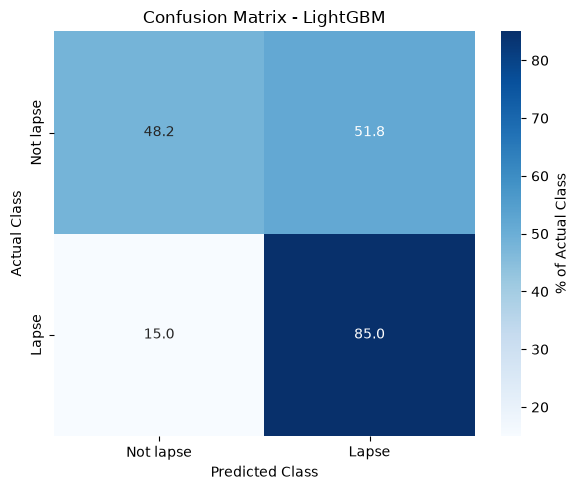

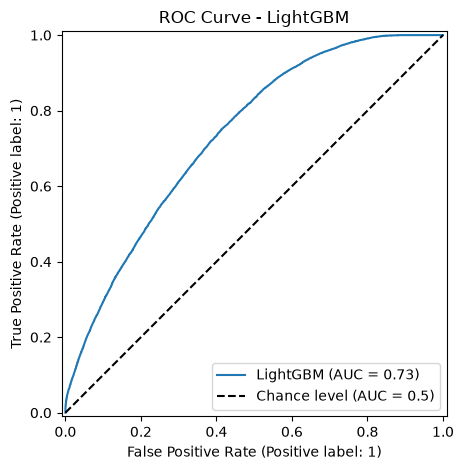

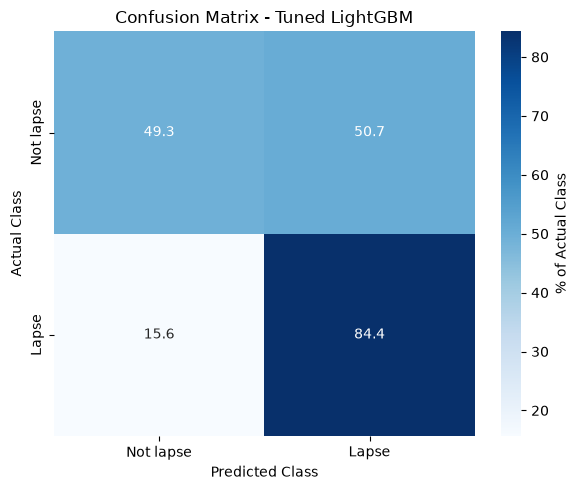

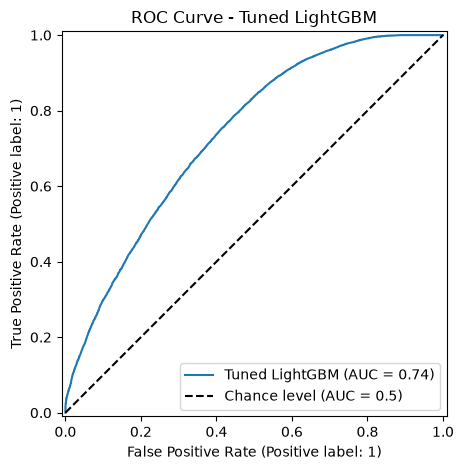

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, RocCurveDisplay)

# Import LightGBM model
from lightgbm import LGBMClassifier

# Import train_test_split, seaborn, matplotlib
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

# Change to your model's name (used in graphs)
MODEL_NAME = "LightGBM"

# Read dataset
df = pd.read_csv("data/CleanedLifeInsurance.csv")

# Define features and target
numeric_features = ["ENTRY AGE", "Policy Year", "BENEFIT", "Premium", "SUBSTANDARD RISK"]
categorical_features = ["PAYMENT MODE"]

X = df[numeric_features + categorical_features]
y = df["is_lapse"]

# Split data into train and test sets (keep random_state = 42 to ensure you get the same data splits every time.)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Preprocess features
# numeric: fill missing values (Premium, BENEFIT) with the median, add a column flagging
# which values were missing, then scale. Scaling doesn't matter for tree models but doesn't hurt.
# categorical: one-hot encode PAYMENT MODE into 0/1 columns.
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Instantiate model
# LightGBM Classifier with default hyperparameters and reproducibility seed
model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train model on training data
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluate performance
print(f"{MODEL_NAME} Performance on Test Set:")
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nMacro F1:", f1_score(y_test, y_pred, average="macro"))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Not lapse", "Lapse"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Graph 1: Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
class_names = ["Not lapse", "Lapse"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "% of Actual Class"}
)
plt.title(f"Confusion Matrix - {MODEL_NAME}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Graph 2: ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob, name=MODEL_NAME, plot_chance_level=True)
plt.title(f"ROC Curve - {MODEL_NAME}")
plt.tight_layout()

# GridSearchCV find-tuning
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# REPLACE WITH HYPERPARAMETERS SPECIFIC TO YOUR MODEL 
param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [-1, 5, 10],
    "num_leaves": [31, 63],
}

REFIT_METRIC = "f1_macro"

grid = GridSearchCV(
    model,
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring={"f1_macro": "f1_macro", "roc_auc": "roc_auc"},
    refit=REFIT_METRIC,
    n_jobs=2,
)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(grid.best_params_)

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print(f"\nTuned {MODEL_NAME} Performance on Test Set:")
print("\nAccuracy:", accuracy_score(y_test, y_pred_tuned))
print("\nMacro F1:", f1_score(y_test, y_pred_tuned, average="macro"))
print("\nROC-AUC:", roc_auc_score(y_test, y_prob_tuned))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=["Not lapse", "Lapse"]))
print("\nConfusion Matrix:")
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print(cm_tuned)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_tuned / cm_tuned.sum(axis=1, keepdims=True) * 100,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=["Not lapse", "Lapse"],
    yticklabels=["Not lapse", "Lapse"],
    cbar_kws={"label": "% of Actual Class"}
)
plt.title(f"Confusion Matrix - Tuned {MODEL_NAME}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

RocCurveDisplay.from_predictions(y_test, y_prob_tuned, name=f"Tuned {MODEL_NAME}", plot_chance_level=True)
plt.title(f"ROC Curve - Tuned {MODEL_NAME}")
plt.tight_layout()
plt.show()